# 04 – WVS Correlation Analysis

## Research Question

To what extent can economic, demographic, social and personal factors explain and predict differences in life satisfaction across countries?

## Objective

This notebook explores the relationships between WVS variables and life satisfaction (Q49).

The analysis aims to:

1. Explore correlations between the available predictor variables and life satisfaction.
2. Identify the strongest associations using Spearman correlation.
3. Apply False Discovery Rate (FDR) correction to account for multiple comparisons.
4. Rank variables according to their association with life satisfaction.
5. Prepare Top 20 and Top 30 feature sets for the subsequent model experiments.

## Important Considerations

- Q49 is the target variable and must never be included as a predictor.
- Correlation does not imply causation.
- Q288 represents relative household income within each country, not absolute income.
- Country differences may influence pooled correlations.
- The analysis uses WVS Wave 7 cross-sectional data.

## Analysis har done in this notebook 

- Variable Discovery
- Special Code Inspection
- Outlier Inspection
- Pooled Spearman Correlation
- Within-country Correlation
- Between-country Correlation
- Feature–Feature Correlation（Top 30）

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)

In [3]:
PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

master_dictionary = pd.read_csv(
    PROJECT_DIR / "outputs" / "feature_selection" /
    "WVS_Master_Variable_Dictionary.csv"
)

train_df = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Train_Clean.csv",
    index_col=0
)

test_df = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Test_Clean.csv",
    index_col=0
)

feature_metadata = pd.read_csv(
    PROCESSED_DATA_DIR / "WVS_Feature_Metadata.csv"
)

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
print("Feature metadata:", feature_metadata.shape)

print("\nTarget distribution:")
print(train_df["Q49"].describe())

Training data: (77360, 243)
Test data: (19340, 243)
Feature metadata: (241, 18)

Target distribution:
count    77360.000000
mean         7.061543
std          2.241049
min          1.000000
25%          6.000000
50%          7.000000
75%          9.000000
max         10.000000
Name: Q49, dtype: float64


In [4]:
# Separate predictors by measurement type

ordinal_features = feature_metadata.loc[
    feature_metadata["Measurement_type"] == "Ordinal",
    "Variable"
].tolist()

binary_features = feature_metadata.loc[
    feature_metadata["Measurement_type"] == "Binary",
    "Variable"
].tolist()

numeric_features = feature_metadata.loc[
    feature_metadata["Measurement_type"] == "Numeric",
    "Variable"
].tolist()

nominal_features = feature_metadata.loc[
    feature_metadata["Measurement_type"] == "Nominal",
    "Variable"
].tolist()

# Spearman candidates
spearman_features = (
    ordinal_features
    + binary_features
    + numeric_features
)

print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))
print("Numeric:", len(numeric_features))
print("Nominal (excluded from Spearman):", len(nominal_features))

print("\nTotal Spearman candidates:", len(spearman_features))

Ordinal: 188
Binary: 26
Numeric: 1
Nominal (excluded from Spearman): 26

Total Spearman candidates: 215


In [5]:
# Count negative values for each candidate

special_code_summary = pd.DataFrame({
    "Variable": spearman_features,
    "Negative_values": [
        (train_df[col] < 0).sum()
        for col in spearman_features
    ]
})

special_code_summary = special_code_summary.sort_values(
    "Negative_values",
    ascending=False
)

print(special_code_summary.head(20).to_string(index=False))

print(
    "\nVariables containing negative values:",
    (special_code_summary["Negative_values"] > 0).sum()
)

Variable  Negative_values
      Q1                0
      Q2                0
      Q3                0
      Q4                0
      Q5                0
      Q6                0
     Q27                0
     Q28                0
     Q29                0
     Q30                0
     Q31                0
     Q32                0
     Q33                0
     Q34                0
     Q35                0
     Q37                0
     Q38                0
     Q39                0
     Q40                0
     Q41                0

Variables containing negative values: 0


In [6]:
# Inspect unique values for each Spearman candidate

value_summary = []

for col in spearman_features:
    values = sorted(train_df[col].dropna().unique())

    value_summary.append({
        "Variable": col,
        "Unique_count": len(values),
        "Min": min(values) if len(values) > 0 else np.nan,
        "Max": max(values) if len(values) > 0 else np.nan,
        "Example_values": values[:15]
    })

value_summary_df = pd.DataFrame(value_summary)

display(
    value_summary_df.sort_values(
        "Unique_count",
        ascending=False
    ).head(30)
)

,Variable,Unique_count,Min,Max,Example_values
214,Q262,84,16.0,103.0,"[16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23...."
180,Q270,33,1.0,63.0,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."
181,Q274,22,0.0,24.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
164,Q243,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
167,Q246,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
165,Q244,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
166,Q245,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
162,Q241,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
169,Q248,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
170,Q249,11,0.0,10.0,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."


In [7]:
# Count common WVS special codes

special_codes = [-1, -2, -3, -4, -5, 97, 98, 99, 997, 998, 999]

special_code_counts = []

for col in spearman_features:
    for code in special_codes:
        count = (train_df[col] == code).sum()

        if count > 0:
            special_code_counts.append({
                "Variable": col,
                "Special_code": code,
                "Count": count
            })

special_code_df = pd.DataFrame(special_code_counts)

if not special_code_df.empty:
    display(
        special_code_df.sort_values(
            "Count",
            ascending=False
        ).head(50)
    )
else:
    print("No tested special codes found.")

,Variable,Special_code,Count
0,Q262,99,9


In [8]:
# Inspect Q262 metadata

display(
    feature_metadata[
        feature_metadata["Variable"] == "Q262"
    ].T
)

,223
Variable,Q262
Feature_group,Basic Demographic Background
Variable_role,Predictor candidate
Model_status,Candidate
Category,Demographic & Background
Column number,338
Data type,int64
Missing count (NaN),0
Missing percentage (NaN),0.0
Unique values (excluding NaN),89


In [9]:
# Inspect observations with Q262 = 99

print("Number of Q262 = 99:")
print((train_df["Q262"] == 99).sum())

print("\nQ262 value counts around 99:")
print(
    train_df["Q262"]
    .value_counts()
    .sort_index()
    .loc[90:103]
)

Number of Q262 = 99:
9

Q262 value counts around 99:
Q262
90.0     23
91.0     31
92.0      9
93.0      9
94.0      7
95.0      4
96.0      2
99.0      9
100.0     1
103.0     1
Name: count, dtype: int64


In [10]:
# Inspect minimum and maximum values

display(
    value_summary_df[
        ["Variable", "Unique_count", "Min", "Max"]
    ].sort_values("Max", ascending=False).head(30)
)

,Variable,Unique_count,Min,Max
214,Q262,84,16.0,103.0
180,Q270,33,1.0,63.0
181,Q274,22,0.0,24.0
74,Q110,10,1.0,10.0
70,Q106,10,1.0,10.0
82,Q120,10,1.0,10.0
75,Q112,10,1.0,10.0
59,Q90,10,1.0,10.0
71,Q107,10,1.0,10.0
72,Q108,10,1.0,10.0


In [11]:
# Inspect Q262 special-code values in training data

print("Q262 missing values:", train_df["Q262"].isna().sum())

print("\nQ262 = 99:")
print((train_df["Q262"] == 99).sum())

print("\nQ262 = 103:")
print((train_df["Q262"] == 103).sum())

print("\nQ262 values above 90:")
print(
    train_df.loc[
        train_df["Q262"] > 90,
        "Q262"
    ].value_counts().sort_index()
)

Q262 missing values: 397

Q262 = 99:
9

Q262 = 103:
1

Q262 values above 90:
Q262
91.0     31
92.0      9
93.0      9
94.0      7
95.0      4
96.0      2
99.0      9
100.0     1
103.0     1
Name: count, dtype: int64


In [12]:
# Check remaining negative values and common special codes

check_codes = [-1, -2, -3, -4, -5, 97, 98, 99, 997, 998, 999]

remaining_codes = []

for col in spearman_features:
    for code in check_codes:
        count = (train_df[col] == code).sum()

        if count > 0:
            remaining_codes.append({
                "Variable": col,
                "Code": code,
                "Count": count
            })

remaining_codes_df = pd.DataFrame(remaining_codes)

print("Variables with remaining candidate codes:",
      remaining_codes_df["Variable"].nunique()
      if not remaining_codes_df.empty else 0)

display(remaining_codes_df)

Variables with remaining candidate codes: 1


,Variable,Code,Count
0,Q262,99,9


## Outlier Inspection

This section investigates potential extreme observations in
numeric and count-based variables.

The objective is to identify unusual values that may represent
data errors or valid but uncommon observations.

Statistical outliers are not automatically removed. Each
observation must be evaluated according to the meaning and
valid range of the corresponding survey variable.

In [13]:
# Inspect numeric and count-based variables

outlier_candidates = ["Q262", "Q270", "Q274"]

for col in outlier_candidates:

    print(f"\n--- {col} ---")

    print(train_df[col].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ))

    print("Unique values:", train_df[col].nunique())
    print("Missing values:", train_df[col].isna().sum())


--- Q262 ---
count    76963.000000
mean        43.185544
std         16.594219
min         16.000000
1%          18.000000
5%          20.000000
25%         29.000000
50%         41.000000
75%         56.000000
95%         72.000000
99%         82.000000
max        103.000000
Name: Q262, dtype: float64
Unique values: 84
Missing values: 397

--- Q270 ---
count    76626.000000
mean         4.017997
std          2.554347
min          1.000000
1%           1.000000
5%           1.000000
25%          2.000000
50%          4.000000
75%          5.000000
95%          8.000000
99%         13.000000
max         63.000000
Name: Q270, dtype: float64
Unique values: 33
Missing values: 734

--- Q274 ---
count    73596.000000
mean         1.774254
std          1.721153
min          0.000000
1%           0.000000
5%           0.000000
25%          0.000000
50%          2.000000
75%          3.000000
95%          5.000000
99%          7.000000
max         24.000000
Name: Q274, dtype: float64
Unique va

In [14]:
# Identify potential outliers using IQR

for col in ["Q262", "Q270", "Q274"]:

    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)

    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    outliers = train_df[
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ]

    print(f"\n--- {col} ---")
    print("Lower fence:", lower)
    print("Upper fence:", upper)
    print("Potential outliers:", len(outliers))

    print("\nValue frequencies:")
    print(outliers[col].value_counts().sort_index())


--- Q262 ---
Lower fence: -11.5
Upper fence: 96.5
Potential outliers: 11

Value frequencies:
Q262
99.0     9
100.0    1
103.0    1
Name: count, dtype: int64

--- Q270 ---
Lower fence: -2.5
Upper fence: 9.5
Potential outliers: 2314

Value frequencies:
Q270
10.0    749
11.0    325
12.0    424
13.0    102
14.0     83
15.0     97
16.0     33
17.0    230
18.0     19
19.0      7
20.0     22
21.0      5
22.0      3
23.0    195
25.0      6
26.0      2
27.0      1
29.0      1
30.0      4
32.0      1
35.0      1
40.0      2
41.0      1
63.0      1
Name: count, dtype: int64

--- Q274 ---
Lower fence: -4.5
Upper fence: 7.5
Potential outliers: 721

Value frequencies:
Q274
8.0     337
9.0     194
10.0     97
11.0     29
12.0     27
13.0      7
14.0      8
15.0      7
16.0      2
17.0      1
18.0      4
21.0      3
22.0      4
24.0      1
Name: count, dtype: int64


In [15]:
# Inspect extreme observations by country

for col, threshold in [
    ("Q262", 96),
    ("Q270", 10),
    ("Q274", 8)
]:

    extreme = train_df[
        train_df[col] >= threshold
    ]

    print(f"\n--- {col} >= {threshold} ---")

    display(
        extreme.groupby(["Country", col])
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
        .head(20)
    )


--- Q262 >= 96 ---


,Country,Q262,Count
2,IRN,99.0,8
0,DEU,96.0,1
1,GBR,96.0,1
3,NGA,100.0,1
4,PHL,103.0,1
5,ZWE,99.0,1



--- Q270 >= 10 ---


,Country,Q270,Count
242,URY,17.0,221
243,URY,23.0,193
241,URY,12.0,151
191,PAK,10.0,73
12,BOL,10.0,56
83,IRQ,10.0,54
85,IRQ,12.0,48
192,PAK,11.0,42
76,IND,10.0,40
223,TJK,10.0,36



--- Q274 >= 8 ---


,Country,Q274,Count
52,JOR,8.0,26
98,NGA,8.0,22
4,BOL,8.0,21
116,PAK,8.0,21
49,IRQ,8.0,20
40,IDN,8.0,18
53,JOR,9.0,18
85,MEX,8.0,17
33,ETH,8.0,15
117,PAK,9.0,14


### Calculate Spearman correlation with Q49

In [16]:
# Calculate Spearman correlation with Q49

correlation_results = []

for col in spearman_features:

    temp = train_df[[col, "Q49"]].dropna()

    if temp[col].nunique() < 2:
        continue

    rho, p_value = spearmanr(
        temp[col],
        temp["Q49"]
    )

    correlation_results.append({
        "Variable": col,
        "Spearman_rho": rho,
        "P_value": p_value,
        "Sample_size": len(temp)
    })

correlation_df = pd.DataFrame(correlation_results)

correlation_df["Abs_rho"] = (
    correlation_df["Spearman_rho"].abs()
)

correlation_df = correlation_df.sort_values(
    "Abs_rho",
    ascending=False
)

display(correlation_df.head(30))

,Variable,Spearman_rho,P_value,Sample_size,Abs_rho
25,Q50,0.560971,0.000000e+00,77054,0.560971
24,Q48,0.459050,0.000000e+00,76865,0.459050
23,Q47,-0.282612,0.000000e+00,77227,0.282612
172,Q251,0.186688,0.000000e+00,75325,0.186688
187,Q288,0.181964,0.000000e+00,75148,0.181964
29,Q54,0.181304,0.000000e+00,76952,0.181304
28,Q53,0.176371,0.000000e+00,76959,0.176371
26,Q51,0.174343,0.000000e+00,77049,0.174343
96,Q159,0.171284,0.000000e+00,75235,0.171284
84,Q131,-0.163581,0.000000e+00,76889,0.163581


In [17]:
# Benjamini-Hochberg FDR correction

reject, p_adjusted, _, _ = multipletests(
    correlation_df["P_value"],
    alpha=0.05,
    method="fdr_bh"
)

correlation_df["FDR_P_value"] = p_adjusted
correlation_df["FDR_Significant"] = reject

correlation_df = correlation_df.sort_values(
    "Abs_rho",
    ascending=False
)

print(
    "FDR-significant variables:",
    correlation_df["FDR_Significant"].sum()
)

display(correlation_df.head(30))

FDR-significant variables: 200


,Variable,Spearman_rho,P_value,Sample_size,Abs_rho,FDR_P_value,FDR_Significant
25,Q50,0.560971,0.000000e+00,77054,0.560971,0.000000e+00,True
24,Q48,0.459050,0.000000e+00,76865,0.459050,0.000000e+00,True
23,Q47,-0.282612,0.000000e+00,77227,0.282612,0.000000e+00,True
172,Q251,0.186688,0.000000e+00,75325,0.186688,0.000000e+00,True
187,Q288,0.181964,0.000000e+00,75148,0.181964,0.000000e+00,True
29,Q54,0.181304,0.000000e+00,76952,0.181304,0.000000e+00,True
28,Q53,0.176371,0.000000e+00,76959,0.176371,0.000000e+00,True
26,Q51,0.174343,0.000000e+00,77049,0.174343,0.000000e+00,True
96,Q159,0.171284,0.000000e+00,75235,0.171284,0.000000e+00,True
84,Q131,-0.163581,0.000000e+00,76889,0.163581,0.000000e+00,True


In [18]:
# Merge correlation results with feature metadata

top30 = correlation_df.head(30).merge(
    feature_metadata[
        ["Variable", "Category", "Measurement_type"]
    ],
    on="Variable",
    how="left"
)

display(
    top30[
        [
            "Variable",
            "Category",
            "Measurement_type",
            "Spearman_rho",
            "FDR_P_value",
            "Sample_size"
        ]
    ]
)

,Variable,Category,Measurement_type,Spearman_rho,FDR_P_value,Sample_size
0,Q50,Economic,Ordinal,0.560971,0.000000e+00,77054
1,Q48,Personal Values & Wellbeing,Ordinal,0.459050,0.000000e+00,76865
2,Q47,Personal Values & Wellbeing,Ordinal,-0.282612,0.000000e+00,77227
3,Q251,Political & Institutional,Ordinal,0.186688,0.000000e+00,75325
4,Q288,Economic,Ordinal,0.181964,0.000000e+00,75148
5,Q54,Economic,Ordinal,0.181304,0.000000e+00,76952
6,Q53,Economic,Ordinal,0.176371,0.000000e+00,76959
7,Q51,Economic,Ordinal,0.174343,0.000000e+00,77049
8,Q159,Science & Technology,Ordinal,0.171284,0.000000e+00,75235
9,Q131,Security,Ordinal,-0.163581,0.000000e+00,76889


In [19]:
# Count categories in Top 30

print(
    top30["Category"]
    .value_counts()
)

Category
Economic                       10
Political & Institutional       8
Personal Values & Wellbeing     5
Science & Technology            3
Security                        3
Social & Community              1
Name: count, dtype: int64


Research Insight: Political Attitudes and Life Satisfaction

Political attitudes may show meaningful individual associations with life satisfaction, while their additional predictive contribution may be limited after accounting for other socioeconomic and personal factors.

In [20]:
# ==========================================
# 1. Merge Top 30 with Feature Group
# ==========================================

top30_category = top30.merge(
    master_dictionary[["Variable", "Feature_group"]],
    on="Variable",
    how="left"
)

# ==========================================
# 2. Create Category Distribution
# ==========================================

category_counts = (
    top30_category["Category"]
    .value_counts(dropna=False)
    .reset_index()
)

category_counts.columns = ["Category", "Count"]


# ==========================================
# 3. Create Feature Group Distribution
# ==========================================

feature_group_counts = (
    top30_category["Feature_group"]
    .value_counts(dropna=False)
    .reset_index()
)

feature_group_counts.columns = ["Feature_group", "Count"]


# ==========================================
# 4. Display Results
# ==========================================

print("Category Distribution:")
display(category_counts)

print("Feature Group Distribution:")
display(feature_group_counts)

Category Distribution:


,Category,Count
0,Economic,10
1,Political & Institutional,8
2,Personal Values & Wellbeing,5
3,Science & Technology,3
4,Security,3
5,Social & Community,1


Feature Group Distribution:


,Feature_group,Count
0,Economic Security,6
1,Political Culture and Democratic Preferences,5
2,Household Economic Position,3
3,Science and Technology Attitudes,3
4,Personal and Neighborhood Security,3
5,Wellbeing,2
6,Institutional confidence,2
7,Economic Values,1
8,General and interpersonal trust,1
9,Ethical Values and Moral Norms,1


In [21]:
# Create output directory
OUTPUT_DIR = PROJECT_DIR / "outputs" / "feature_discovery"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save Spearman correlation ranking
correlation_df.to_csv(
    OUTPUT_DIR / "WVS_Spearman_Correlation_Ranking.csv",
    index=False
)

# Save Top 30 correlation results
top30.to_csv(
    OUTPUT_DIR / "WVS_Top30_Correlation_Results.csv",
    index=False
)

# Save Category Distribution
category_counts.to_csv(
    OUTPUT_DIR / "WVS_Top30_Category_Distribution.csv",
    index=False
)

# Save Feature Group Distribution
feature_group_counts.to_csv(
    OUTPUT_DIR / "WVS_Top30_Feature_Group_Distribution.csv",
    index=False
)

print("All correlation analysis results saved successfully!")

All correlation analysis results saved successfully!


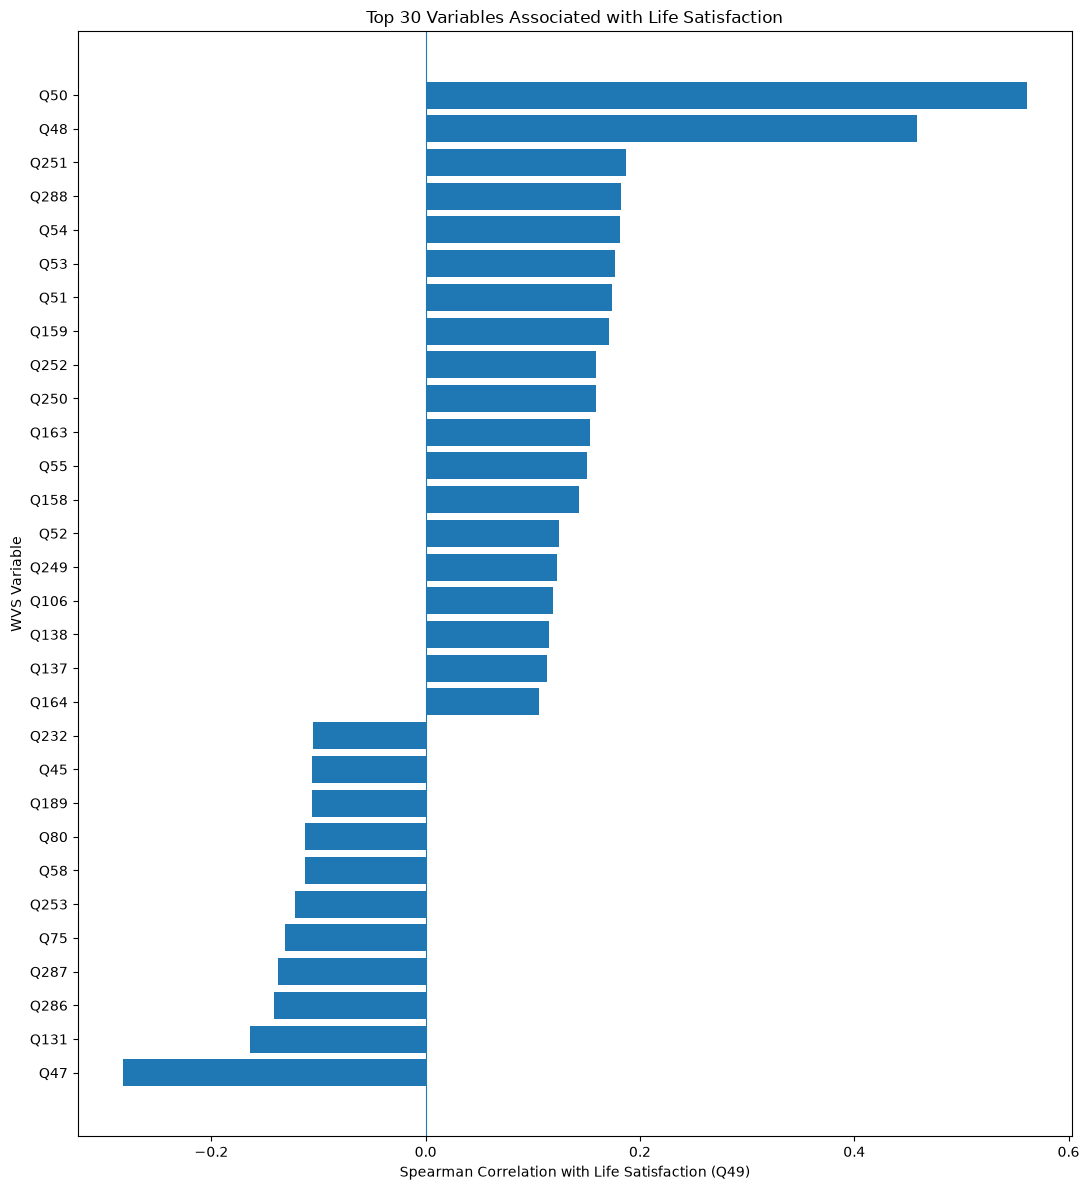

In [22]:
# Plot Top 30 Spearman correlations

plot_df = top30.sort_values(
    "Spearman_rho",
    ascending=True
)

plt.figure(figsize=(11, 12))

plt.barh(
    plot_df["Variable"],
    plot_df["Spearman_rho"]
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("Spearman Correlation with Life Satisfaction (Q49)")
plt.ylabel("WVS Variable")
plt.title("Top 30 Variables Associated with Life Satisfaction")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "WVS_Top30_Correlation_Ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

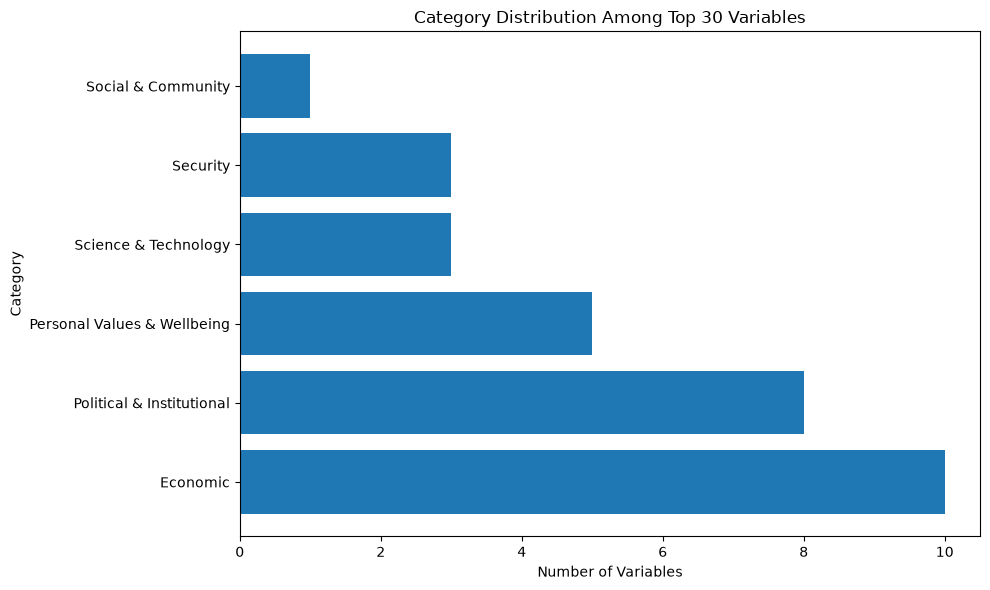

In [23]:
# Plot category distribution

plt.figure(figsize=(10, 6))

plt.barh(
    category_counts["Category"],
    category_counts["Count"]
)

plt.xlabel("Number of Variables")
plt.ylabel("Category")
plt.title("Category Distribution Among Top 30 Variables")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "WVS_Top30_Category_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# Create Top 20 and Top 30 feature lists

top20_features = (
    correlation_df.head(20)["Variable"].tolist()
)

top30_features = (
    correlation_df.head(30)["Variable"].tolist()
)

print("Top 20 features:", len(top20_features))
print("Top 30 features:", len(top30_features))

print("\nTop 20:")
print(top20_features)

print("\nAdditional 10 features:")
print([
    feature for feature in top30_features
    if feature not in top20_features
])

Top 20 features: 20
Top 30 features: 30

Top 20:
['Q50', 'Q48', 'Q47', 'Q251', 'Q288', 'Q54', 'Q53', 'Q51', 'Q159', 'Q131', 'Q252', 'Q250', 'Q163', 'Q55', 'Q158', 'Q286', 'Q287', 'Q75', 'Q52', 'Q249']

Additional 10 features:
['Q253', 'Q106', 'Q138', 'Q137', 'Q58', 'Q80', 'Q189', 'Q45', 'Q164', 'Q232']


In [25]:
# Save feature lists

pd.DataFrame({
    "Rank": range(1, 21),
    "Variable": top20_features
}).to_csv(
    OUTPUT_DIR / "WVS_Top20_Features.csv",
    index=False
)

pd.DataFrame({
    "Rank": range(1, 31),
    "Variable": top30_features
}).to_csv(
    OUTPUT_DIR / "WVS_Top30_Features.csv",
    index=False
)

print("Top 20 and Top 30 feature lists saved.")

Top 20 and Top 30 feature lists saved.


## 7. Within-country Correlation Analysis

### Objective

Investigate whether the associations between WVS variables and life satisfaction are consistent within individual countries.

### Research Questions

1. Do pooled correlations reflect relationships within individual countries?
2. Are the directions of correlations consistent across countries?
3. How much does the strength of correlations vary between countries?

### Method

Spearman correlations will be calculated separately for each country.

Only countries with at least 30 valid observations for a given variable will be included in the country-level analysis.

The results will be compared with pooled Spearman correlations.

### Important Considerations

Country-level correlations describe associations within countries, not causal effects.

The number of valid observations may differ between countries and variables.

In [26]:
# Check country distribution in training data

country_counts = (
    train_df["Country"]
    .value_counts()
    .rename_axis("Country")
    .reset_index(name="Respondents")
)

print("Number of countries:", len(country_counts))

display(country_counts.describe())

display(country_counts.sort_values("Respondents"))

Number of countries: 66


,Respondents
count,66.000000
mean,1172.121212
std,470.361743
min,357.000000
25%,949.750000
50%,987.500000
75%,1285.000000
max,3206.000000


,Country,Respondents
65,NIR,357
64,URY,765
63,CYP,791
61,AND,803
62,CHL,803
...,...,...
4,GBR,2050
3,USA,2112
2,CHN,2433
1,IDN,2528


In [27]:
# Calculate within-country Spearman correlations

within_country_results = []

for country in train_df["Country"].dropna().unique():

    country_df = train_df[
        train_df["Country"] == country
    ]

    for col in spearman_features:

        temp = country_df[[col, "Q49"]].dropna()

        if len(temp) < 30:
            continue

        if temp[col].nunique() < 2:
            continue

        rho, p_value = spearmanr(
            temp[col],
            temp["Q49"]
        )

        within_country_results.append({
            "Country": country,
            "Variable": col,
            "Spearman_rho": rho,
            "P_value": p_value,
            "Sample_size": len(temp)
        })

within_country_df = pd.DataFrame(
    within_country_results
)

print("Countries analyzed:",
      within_country_df["Country"].nunique())

print("Correlation observations:",
      len(within_country_df))

print("Variables analyzed:",
      within_country_df["Variable"].nunique())

display(within_country_df.head(20))

Countries analyzed: 66
Correlation observations: 14069
Variables analyzed: 215


,Country,Variable,Spearman_rho,P_value,Sample_size
0,HKG,Q1,-0.194196,3.015538e-15,1622
1,HKG,Q2,-0.057275,2.106496e-02,1622
2,HKG,Q3,0.005048,8.393042e-01,1616
3,HKG,Q4,0.015853,5.244992e-01,1614
4,HKG,Q5,-0.039940,1.080653e-01,1620
5,HKG,Q6,-0.056513,2.301002e-02,1618
6,HKG,Q27,-0.051976,3.668860e-02,1616
7,HKG,Q28,0.018063,4.682066e-01,1615
8,HKG,Q29,0.040198,1.068892e-01,1610
9,HKG,Q30,0.028229,2.560075e-01,1621


In [28]:
# Inspect country-level correlation coverage

coverage = (
    within_country_df.groupby("Variable")
    .agg(
        Countries_analyzed=("Country", "nunique"),
        Mean_rho=("Spearman_rho", "mean"),
        Median_rho=("Spearman_rho", "median"),
        Positive_countries=(
            "Spearman_rho",
            lambda x: (x > 0).sum()
        ),
        Negative_countries=(
            "Spearman_rho",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

coverage["Positive_country_percentage"] = (
    coverage["Positive_countries"]
    / coverage["Countries_analyzed"] * 100
)

display(
    coverage.sort_values(
        "Countries_analyzed",
        ascending=True
    ).head(20)
)

,Variable,Countries_analyzed,Mean_rho,Median_rho,Positive_countries,Negative_countries,Positive_country_percentage
137,Q263,56,-0.005882,-0.005666,26,30,46.428571
61,Q183,61,-0.056842,-0.061824,12,49,19.672131
101,Q226,61,0.023032,0.018148,35,26,57.377049
72,Q193,62,-0.063072,-0.072851,11,51,17.741935
48,Q165,62,-0.032984,-0.024746,16,46,25.806452
15,Q115,63,-0.060340,-0.065407,12,51,19.047619
143,Q278,63,0.024181,0.030609,42,21,66.666667
60,Q182,63,-0.016714,-0.031857,24,39,38.095238
142,Q277,63,0.021942,0.019607,38,25,60.317460
33,Q144,64,0.059278,0.061401,53,11,82.812500


## 8. Comparing Pooled and Within-country Correlations

This section compares pooled Spearman correlations with the
distribution of within-country correlations.

The objective is to investigate whether associations observed
across all respondents are also present within individual countries.

The comparison helps identify potential differences between
pooled and country-specific relationships.

These results are descriptive and do not establish causality.

In [29]:
# Select important variables from the pooled analysis

selected_vars = [
    "Q50", "Q251", "Q288", "Q159",
    "Q131", "Q48", "Q47"
]

# Summarise within-country correlations

within_summary = (
    within_country_df[
        within_country_df["Variable"].isin(selected_vars)
    ]
    .groupby("Variable")
    .agg(
        Countries=("Country", "nunique"),
        Mean_rho=("Spearman_rho", "mean"),
        Median_rho=("Spearman_rho", "median"),
        Std_rho=("Spearman_rho", "std"),
        Positive_countries=(
            "Spearman_rho",
            lambda x: (x > 0).sum()
        ),
        Negative_countries=(
            "Spearman_rho",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

# Add pooled correlations

comparison_df = correlation_df[
    correlation_df["Variable"].isin(selected_vars)
][["Variable", "Spearman_rho"]].rename(
    columns={"Spearman_rho": "Pooled_rho"}
)

comparison_df = comparison_df.merge(
    within_summary,
    on="Variable",
    how="left"
)

display(
    comparison_df.sort_values(
        "Pooled_rho",
        key=abs,
        ascending=False
    )
)

,Variable,Pooled_rho,Countries,Mean_rho,Median_rho,Std_rho,Positive_countries,Negative_countries
0,Q50,0.560971,66,0.538171,0.544678,0.106343,66,0
1,Q48,0.459050,66,0.445202,0.446565,0.127440,66,0
2,Q47,-0.282612,66,-0.279587,-0.287051,0.113474,0,66
3,Q251,0.186688,66,0.159378,0.167310,0.101966,60,6
4,Q288,0.181964,66,0.191158,0.193033,0.138067,63,3
5,Q159,0.171284,65,0.175196,0.168682,0.083175,65,0
6,Q131,-0.163581,66,-0.177558,-0.171395,0.076312,0,66


## 9. Between-country Correlation Analysis

This section examines associations at the country level.

For each country, mean values are calculated for life satisfaction
and the selected explanatory variables.

Spearman correlations are then calculated across countries.

This analysis explores whether country-level differences in
selected variables are associated with country-level differences
in life satisfaction.

Country-level associations must not be interpreted as
individual-level relationships.

In [30]:
# Select variables for country-level analysis

selected_vars = [
    "Q50", "Q48", "Q47", "Q251",
    "Q288", "Q159", "Q131"
]

# Calculate country-level means

country_means = (
    train_df.groupby("Country")[selected_vars + ["Q49"]]
    .mean()
)

display(country_means.head())

,Q50,Q48,Q47,Q251,Q288,Q159,Q131,Q49
Country,,,,,,,,
AND,6.581047,7.457036,1.920299,6.618570,5.393512,7.273067,1.280549,7.537983
ARG,5.985203,7.796778,2.154982,7.042447,5.113402,7.769328,2.419951,7.694103
ARM,5.240042,7.764768,2.735356,5.094714,4.697257,8.990476,2.394737,6.575758
AUS,6.647059,7.658020,2.038225,7.391244,5.101826,7.047782,2.006139,7.530169
BGD,7.022358,7.292683,2.294715,7.266260,5.609756,8.650407,1.838250,7.610772


In [31]:
# Calculate between-country Spearman correlations

between_country_results = []

for col in selected_vars:

    temp = country_means[[col, "Q49"]].dropna()

    rho, p_value = spearmanr(
        temp[col],
        temp["Q49"]
    )

    between_country_results.append({
        "Variable": col,
        "Spearman_rho": rho,
        "P_value": p_value,
        "Number_of_countries": len(temp)
    })

between_country_df = pd.DataFrame(
    between_country_results
)

display(
    between_country_df.sort_values(
        "Spearman_rho",
        key=abs,
        ascending=False
    )
)

,Variable,Spearman_rho,P_value,Number_of_countries
0,Q50,0.818808,4.512501e-17,66
1,Q48,0.746039,6.569974e-13,66
3,Q251,0.344703,4.592615e-03,66
2,Q47,-0.285043,2.035123e-02,66
4,Q288,0.225968,6.809562e-02,66
6,Q131,-0.096754,4.396227e-01,66
5,Q159,0.051836,6.817476e-01,65


In [32]:
# Apply FDR correction to between-country correlations

reject, adjusted_p, _, _ = multipletests(
    between_country_df["P_value"],
    alpha=0.05,
    method="fdr_bh"
)

between_country_df["FDR_P_value"] = adjusted_p
between_country_df["FDR_Significant"] = reject

display(
    between_country_df.sort_values(
        "Spearman_rho",
        key=abs,
        ascending=False
    )
)

,Variable,Spearman_rho,P_value,Number_of_countries,FDR_P_value,FDR_Significant
0,Q50,0.818808,4.512501e-17,66,3.158751e-16,True
1,Q48,0.746039,6.569974e-13,66,2.299491e-12,True
3,Q251,0.344703,4.592615e-03,66,1.071610e-02,True
2,Q47,-0.285043,2.035123e-02,66,3.561465e-02,True
4,Q288,0.225968,6.809562e-02,66,9.533387e-02,False
6,Q131,-0.096754,4.396227e-01,66,5.128932e-01,False
5,Q159,0.051836,6.817476e-01,65,6.817476e-01,False


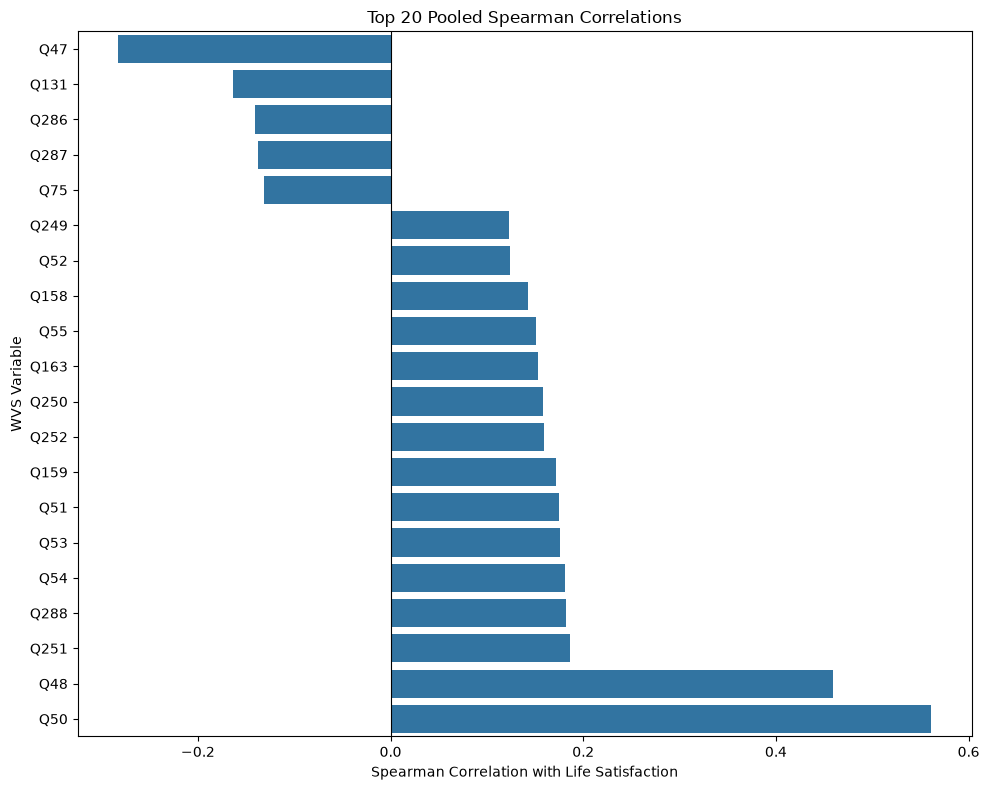

In [33]:
# Visualize the strongest pooled correlations

top_corr = correlation_df.head(20).sort_values(
    "Spearman_rho"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_corr,
    x="Spearman_rho",
    y="Variable"
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top 20 Pooled Spearman Correlations")
plt.xlabel("Spearman Correlation with Life Satisfaction")
plt.ylabel("WVS Variable")

plt.tight_layout()
plt.show()

**Key Findings**

Q50 and Q48 show the strongest positive associations with life satisfaction, while Q47 shows the strongest negative association.

Most of the remaining variables have relatively modest correlations. This suggests that life satisfaction is associated with several different dimensions rather than being explained by a single factor.

These are individual, pooled associations and do not indicate independent predictive contributions or causal relationships.

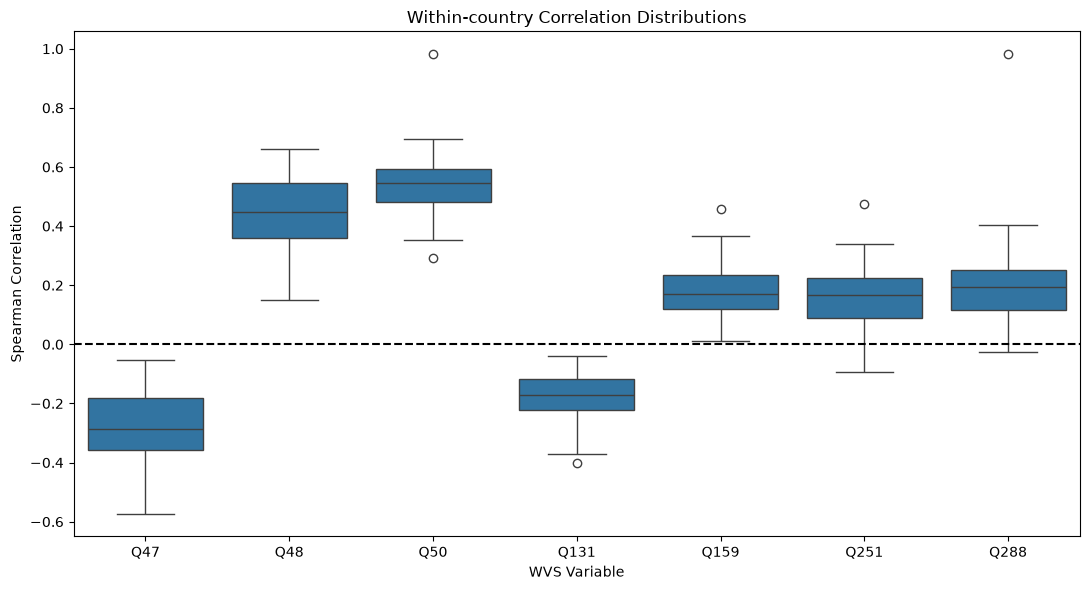

In [34]:
# Compare within-country correlation distributions

selected_vars = [
    "Q50", "Q48", "Q47",
    "Q251", "Q288", "Q159", "Q131"
]

plot_data = within_country_df[
    within_country_df["Variable"].isin(selected_vars)
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=plot_data,
    x="Variable",
    y="Spearman_rho"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Within-country Correlation Distributions")
plt.xlabel("WVS Variable")
plt.ylabel("Spearman Correlation")

plt.tight_layout()
plt.show()

**Key Findings**

Q50 and Q48 show consistently positive correlations across countries, while Q47 and Q131 show consistently negative correlations.

Q159, Q251 and Q288 are also predominantly positively associated with life satisfaction, although their correlation strengths vary across countries.

The distributions highlight that some relationships are relatively consistent internationally, while others show greater country-level variation. The outlier points represent countries with unusual correlation coefficients, not individual respondent outliers.

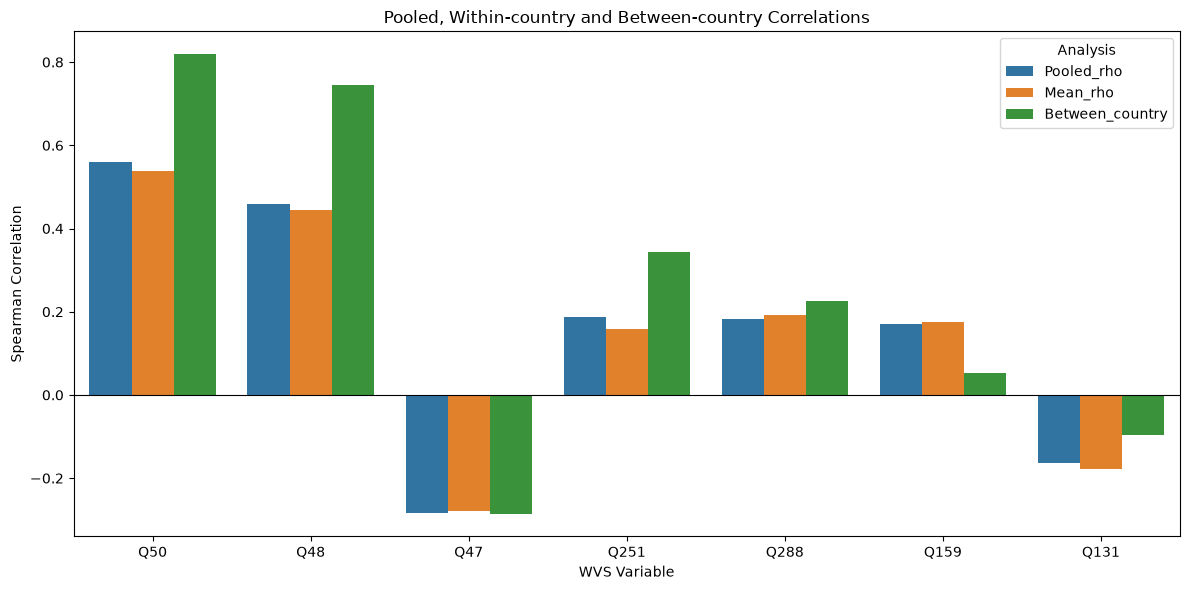

In [35]:
# Prepare comparison data

comparison_plot = comparison_df.melt(
    id_vars="Variable",
    value_vars=["Pooled_rho", "Mean_rho"],
    var_name="Analysis",
    value_name="Spearman_rho"
)

between_plot = between_country_df[
    ["Variable", "Spearman_rho"]
].copy()

between_plot["Analysis"] = "Between_country"

between_plot = between_plot.rename(
    columns={"Spearman_rho": "Spearman_rho"}
)

comparison_plot = pd.concat(
    [comparison_plot, between_plot],
    ignore_index=True
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Variable",
    y="Spearman_rho",
    hue="Analysis"
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Pooled, Within-country and Between-country Correlations")
plt.xlabel("WVS Variable")
plt.ylabel("Spearman Correlation")

plt.tight_layout()
plt.show()

**Key Findings**

The comparison shows that the relationships between several variables and life satisfaction differ across analytical levels.

Q50 and Q48 demonstrate consistently positive associations at both individual and country levels. In contrast, Q159 shows a positive association at the individual level but almost no association at the country level.

This illustrates that individual-level relationships cannot automatically be generalized to country-level patterns. The findings highlight the importance of distinguishing individual and country-level associations.

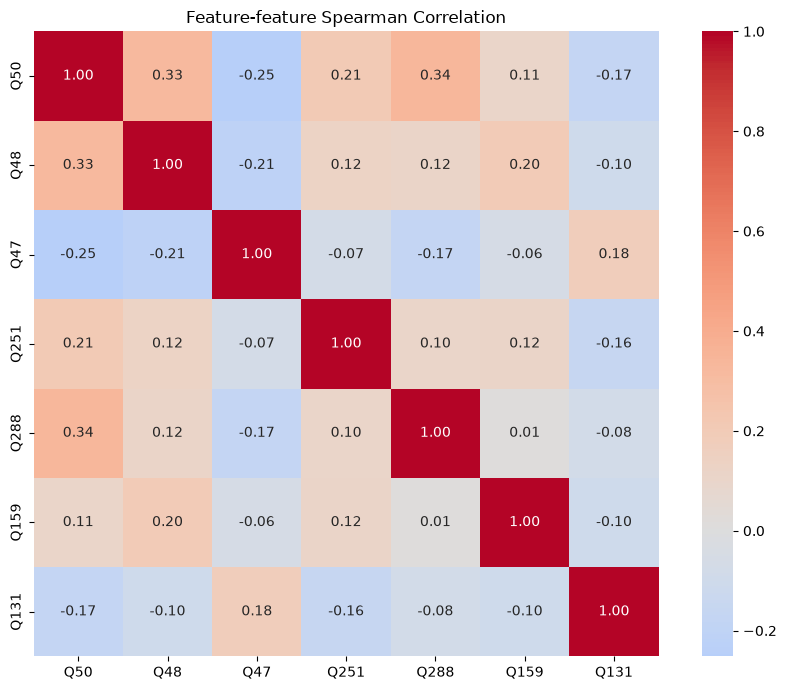

In [36]:
# Select important variables

heatmap_vars = [
    "Q50", "Q48", "Q47",
    "Q251", "Q288", "Q159", "Q131"
]

# Calculate feature-feature Spearman correlations

feature_corr = train_df[heatmap_vars].corr(
    method="spearman"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Feature-feature Spearman Correlation")
plt.tight_layout()
plt.show()

**Key Findings**

The selected features show mostly weak to moderate pairwise correlations.

The strongest positive relationships are observed between Q50 and Q288 (0.34), and Q50 and Q48 (0.33). No pair among the selected variables shows an especially strong correlation.

This suggests that the selected variables may capture partly different dimensions of life satisfaction. However, pairwise correlations alone cannot determine how much predictive information is shared between features. Further multivariable analysis is required.

In [37]:
# Identify potential outliers using IQR

for col in ["Q262", "Q270", "Q274"]:

    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)

    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    outliers = train_df[
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ]

    print(f"\n--- {col} ---")
    print("Lower fence:", lower)
    print("Upper fence:", upper)
    print("Potential outliers:", len(outliers))

    print("\nValue frequencies:")
    print(outliers[col].value_counts().sort_index())


--- Q262 ---
Lower fence: -11.5
Upper fence: 96.5
Potential outliers: 11

Value frequencies:
Q262
99.0     9
100.0    1
103.0    1
Name: count, dtype: int64

--- Q270 ---
Lower fence: -2.5
Upper fence: 9.5
Potential outliers: 2314

Value frequencies:
Q270
10.0    749
11.0    325
12.0    424
13.0    102
14.0     83
15.0     97
16.0     33
17.0    230
18.0     19
19.0      7
20.0     22
21.0      5
22.0      3
23.0    195
25.0      6
26.0      2
27.0      1
29.0      1
30.0      4
32.0      1
35.0      1
40.0      2
41.0      1
63.0      1
Name: count, dtype: int64

--- Q274 ---
Lower fence: -4.5
Upper fence: 7.5
Potential outliers: 721

Value frequencies:
Q274
8.0     337
9.0     194
10.0     97
11.0     29
12.0     27
13.0      7
14.0      8
15.0      7
16.0      2
17.0      1
18.0      4
21.0      3
22.0      4
24.0      1
Name: count, dtype: int64


In [38]:
# Inspect extreme observations by country

for col, threshold in [
    ("Q262", 96),
    ("Q270", 10),
    ("Q274", 8)
]:

    extreme = train_df[
        train_df[col] >= threshold
    ]

    print(f"\n--- {col} >= {threshold} ---")

    display(
        extreme.groupby(["Country", col])
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
        .head(20)
    )


--- Q262 >= 96 ---


,Country,Q262,Count
2,IRN,99.0,8
0,DEU,96.0,1
1,GBR,96.0,1
3,NGA,100.0,1
4,PHL,103.0,1
5,ZWE,99.0,1



--- Q270 >= 10 ---


,Country,Q270,Count
242,URY,17.0,221
243,URY,23.0,193
241,URY,12.0,151
191,PAK,10.0,73
12,BOL,10.0,56
83,IRQ,10.0,54
85,IRQ,12.0,48
192,PAK,11.0,42
76,IND,10.0,40
223,TJK,10.0,36



--- Q274 >= 8 ---


,Country,Q274,Count
52,JOR,8.0,26
98,NGA,8.0,22
4,BOL,8.0,21
116,PAK,8.0,21
49,IRQ,8.0,20
40,IDN,8.0,18
53,JOR,9.0,18
85,MEX,8.0,17
33,ETH,8.0,15
117,PAK,9.0,14


In [39]:
# Identify numeric and count-based variables

numeric_candidates = ["Q262", "Q270", "Q274"]

outlier_summary = []

for col in numeric_candidates:

    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = train_df[
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ]

    outlier_summary.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "Lower_fence": lower,
        "Upper_fence": upper,
        "Outlier_count": len(outliers),
        "Outlier_percentage": len(outliers) / train_df[col].notna().sum() * 100
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df)

,Variable,Q1,Q3,Lower_fence,Upper_fence,Outlier_count,Outlier_percentage
0,Q262,29.0,56.0,-11.5,96.5,11,0.014293
1,Q270,2.0,5.0,-2.5,9.5,2314,3.019863
2,Q274,0.0,3.0,-4.5,7.5,721,0.979673


In [40]:
# Inspect measurement types in metadata

display(
    feature_metadata[
        ["Variable", "Measurement_type"]
    ]["Measurement_type"]
    .value_counts()
)

Measurement_type
Ordinal    188
Binary      26
Nominal     26
Numeric      1
Name: count, dtype: int64

In [41]:
# Identify numeric and count-based variables

numeric_variables = feature_metadata.loc[
    feature_metadata["Measurement_type"] == "Numeric",
    "Variable"
].tolist()

# Add count-based variables identified during data inspection

numeric_variables = sorted(
    set(numeric_variables + ["Q270", "Q274"])
)

print("Variables selected for outlier inspection:")
print(numeric_variables)

Variables selected for outlier inspection:
['Q262', 'Q270', 'Q274']


In [42]:
numeric_variables = sorted(
    set(numeric_variables + ["Q270", "Q274"])
)

print(numeric_variables)

['Q262', 'Q270', 'Q274']


In [43]:
display(
    feature_metadata[
        ["Variable", "Data type", "Measurement_type"]
    ].sort_values("Variable")
)

,Variable,Data type,Measurement_type
0,Q1,int64,Ordinal
9,Q10,int64,Binary
87,Q100,int64,Ordinal
88,Q101,int64,Ordinal
89,Q102,int64,Ordinal
...,...,...,...
82,Q95,int64,Ordinal
83,Q96,int64,Ordinal
84,Q97,int64,Ordinal
85,Q98,int64,Ordinal


## Value Range Validation

This section checks whether variables contain values outside
their expected response ranges.

The purpose is to identify potentially invalid survey responses
and coding inconsistencies.

Valid but uncommon responses are retained unless evidence
indicates that they represent data errors.

In [44]:
# Q270, Q274 should be numeric instead of Ordinal
feature_metadata.loc[
    feature_metadata["Variable"].isin(["Q270", "Q274"]),
    "Measurement_type"
] = "Numeric"

# recreate numeric list
numeric_variables = sorted(
    feature_metadata.loc[
        feature_metadata["Measurement_type"] == "Numeric",
        "Variable"
    ].tolist()
)

print("Numeric variables:", numeric_variables)

Numeric variables: ['Q262', 'Q270', 'Q274']


In [45]:
# check the distribution of those three numeric variables
for variable in numeric_variables:
    print(f"\n--- {variable} ---")

    print(
        train_df[variable].describe(
            percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        )
    )

    print("\nHighest values:")
    print(
        train_df[variable]
        .value_counts()
        .sort_index()
        .tail(15)
    )


--- Q262 ---
count    76963.000000
mean        43.185544
std         16.594219
min         16.000000
1%          18.000000
5%          20.000000
25%         29.000000
50%         41.000000
75%         56.000000
95%         72.000000
99%         82.000000
max        103.000000
Name: Q262, dtype: float64

Highest values:
Q262
85.0     105
86.0      77
87.0      53
88.0      49
89.0      41
90.0      23
91.0      31
92.0       9
93.0       9
94.0       7
95.0       4
96.0       2
99.0       9
100.0      1
103.0      1
Name: count, dtype: int64

--- Q270 ---
count    76626.000000
mean         4.017997
std          2.554347
min          1.000000
1%           1.000000
5%           1.000000
25%          2.000000
50%          4.000000
75%          5.000000
95%          8.000000
99%         13.000000
max         63.000000
Name: Q270, dtype: float64

Highest values:
Q270
19.0      7
20.0     22
21.0      5
22.0      3
23.0    195
25.0      6
26.0      2
27.0      1
29.0      1
30.0      4
32.0 

In [46]:
# Examine high values by country

outlier_checks = {
    "Q262": 90,
    "Q270": 10,
    "Q274": 8
}

for variable, threshold in outlier_checks.items():

    print(f"\n{'=' * 50}")
    print(f"{variable}: values >= {threshold}")
    print(f"{'=' * 50}")

    high_values = train_df[
        train_df[variable] >= threshold
    ]

    country_summary = (
        high_values
        .groupby("Country")[variable]
        .agg(["count", "min", "max"])
        .sort_values("count", ascending=False)
    )

    print(country_summary.head(20))
    print(f"\nTotal observations: {len(high_values)}")
    print(f"Countries affected: {high_values['Country'].nunique()}")


Q262: values >= 90
         count    min    max
Country                     
GBR         17   90.0   96.0
AUS         14   90.0   94.0
IRN          9   90.0   99.0
JPN          7   91.0   94.0
DEU          7   91.0   96.0
PRI          4   91.0   94.0
ARG          3   91.0   93.0
GRC          3   90.0   92.0
NLD          3   91.0   93.0
RUS          3   90.0   91.0
ARM          3   90.0   91.0
AND          2   90.0   90.0
SGP          2   90.0   91.0
SRB          2   91.0   93.0
HKG          2   91.0   91.0
NIR          2   90.0   90.0
NZL          2   91.0   91.0
BRA          1   91.0   91.0
CAN          1   93.0   93.0
NGA          1  100.0  100.0

Total observations: 96
Countries affected: 28

Q270: values >= 10
         count   min   max
Country                   
URY        569  10.0  23.0
PAK        192  10.0  22.0
NGA        157  10.0  63.0
IRQ        130  10.0  12.0
TJK        114  10.0  20.0
BOL        108  10.0  21.0
MDV        108  10.0  26.0
IND         98  10.0  15.0
NIC  

In [47]:
# Inspect household sizes of 20 or more

q270_extreme = train_df.loc[
    train_df["Q270"] >= 20,
    ["Country", "Q270", "Q49"]
].copy()

# Count observations by country and household size
q270_country_distribution = (
    q270_extreme
    .groupby(["Country", "Q270"])
    .size()
    .reset_index(name="Count")
    .sort_values(
        ["Q270", "Count"],
        ascending=[False, False]
    )
)

print("Number of observations:", len(q270_extreme))
print("Number of countries:", q270_extreme["Country"].nunique())

display(q270_country_distribution)

Number of observations: 245
Number of countries: 14


,Country,Q270,Count
29,NGA,63.0,1
12,LBY,41.0,1
18,MYS,40.0,1
28,NGA,40.0,1
27,NGA,35.0,1
11,LBY,32.0,1
26,NGA,30.0,3
6,KEN,30.0,1
2,BRA,29.0,1
25,NGA,27.0,1


In [48]:
# Examine household size distribution in Uruguay

ury_q270 = (
    train_df.loc[
        train_df["Country"] == "URY",
        "Q270"
    ]
    .value_counts()
    .sort_index()
)

print("URY household size distribution:")
print(ury_q270)

print("\nTotal valid observations:", ury_q270.sum())
print("Median household size:", train_df.loc[
    train_df["Country"] == "URY", "Q270"
].median())

URY household size distribution:
Q270
4.0      50
6.0      19
7.0       8
8.0     119
10.0      1
11.0      3
12.0    151
17.0    221
23.0    193
Name: count, dtype: int64

Total valid observations: 765
Median household size: 17.0


In [49]:
# Compare URY household size with other countries

country_q270_summary = (
    train_df
    .groupby("Country")["Q270"]
    .agg(
        ["count", "median", "mean", "max"]
    )
    .sort_values("median", ascending=False)
)

display(country_q270_summary.head(15))

,count,median,mean,max
Country,,,,
URY,765,17.0,14.866667,23.0
LBY,937,6.0,6.023479,41.0
PAK,1588,6.0,6.359572,22.0
TJK,981,6.0,6.384302,20.0
MDV,787,6.0,6.349428,26.0
IRQ,971,6.0,6.432544,12.0
MAR,944,5.0,4.925847,11.0
NGA,1007,5.0,6.307845,63.0
BOL,1617,5.0,5.206555,21.0


### Outlier Inspection – Summary and Decisions

An outlier inspection was conducted for the three numerical variables Q262 (Age), Q270 (Household Size) and Q274 (Number of Children).

The IQR method was used to identify unusually high observations. However, statistical outliers were not automatically classified as invalid data.

**Q262 – Age**
- 11 observations were flagged by the IQR method.
- High ages were distributed across 28 countries.
- Values such as 99, 100 and 103 were retained provisionally because their validity could not be conclusively determined from the available data.

**Q270 – Household Size**
- 2,314 observations had household sizes of 10 or more.
- These observations were distributed across 55 countries.
- Some extreme values were identified, including a maximum of 63.
- Uruguay showed a notable concentration of respondents reporting a household size of 23.
- These observations were retained because there was insufficient evidence to classify them as data errors.

**Q274 – Number of Children**
- 721 observations reported eight or more children.
- These observations were distributed across 50 countries.
- The maximum value was 24.
- High values were retained because they may represent genuine family circumstances.

**Final decision**

No observations were removed or modified during outlier inspection. All three variables were retained for subsequent analysis.

The IQR method identifies statistically unusual observations but does not establish that they are incorrect. Removing potentially valid observations could reduce the representativeness of the dataset.

The impact of these observations may be considered later through model evaluation and sensitivity analysis.

## Feature–Feature Correlation Analysis

This section examines correlations among the Top 30 predictors identified
through their Spearman correlations with life satisfaction (Q49).

The purpose is to identify potentially redundant predictors and investigate
whether some features provide overlapping information.

High correlation does not automatically mean that a feature should be removed.

In [50]:
# Load the Top 30 feature ranking
top30_path = OUTPUT_DIR / "WVS_Top30_Correlation_Results.csv"

top30_results = pd.read_csv(top30_path)

top30_variables = top30_results["Variable"].tolist()

print("Number of Top 30 variables:", len(top30_variables))
print(top30_variables)

Number of Top 30 variables: 30
['Q50', 'Q48', 'Q47', 'Q251', 'Q288', 'Q54', 'Q53', 'Q51', 'Q159', 'Q131', 'Q252', 'Q250', 'Q163', 'Q55', 'Q158', 'Q286', 'Q287', 'Q75', 'Q52', 'Q249', 'Q253', 'Q106', 'Q138', 'Q137', 'Q58', 'Q80', 'Q189', 'Q45', 'Q164', 'Q232']


In [51]:
# Select Top 30 predictors from the training data
top30_data = train_df[top30_variables].copy()

# Calculate pairwise Spearman correlations
top30_corr_matrix = top30_data.corr(
    method="spearman",
    min_periods=30
)

print("Correlation matrix shape:", top30_corr_matrix.shape)

display(top30_corr_matrix.round(2))

Correlation matrix shape: (30, 30)


,Q50,Q48,Q47,Q251,Q288,Q54,Q53,Q51,Q159,Q131,Q252,Q250,Q163,Q55,Q158,Q286,Q287,Q75,Q52,Q249,Q253,Q106,Q138,Q137,Q58,Q80,Q189,Q45,Q164,Q232
Q50,1.00,0.33,-0.25,0.21,0.34,0.30,0.24,0.25,0.11,-0.17,0.22,0.09,0.13,0.15,0.10,-0.26,-0.25,-0.12,0.15,0.08,-0.16,0.10,0.09,0.13,-0.11,-0.10,-0.05,-0.04,-0.01,-0.09
Q48,0.33,1.00,-0.21,0.12,0.12,0.07,0.09,0.09,0.20,-0.10,0.07,0.19,0.16,0.09,0.18,-0.08,-0.08,-0.10,0.07,0.14,-0.05,0.15,0.07,0.06,-0.08,-0.08,-0.11,-0.12,0.14,-0.08
Q47,-0.25,-0.21,1.00,-0.07,-0.17,-0.13,-0.17,-0.12,-0.06,0.18,-0.07,-0.05,-0.09,-0.08,-0.07,0.12,0.14,0.08,-0.10,-0.03,0.10,-0.06,-0.06,-0.06,0.12,0.07,0.04,0.02,-0.02,0.03
Q251,0.21,0.12,-0.07,1.00,0.10,0.10,0.10,0.08,0.12,-0.16,0.61,0.19,0.18,0.05,0.13,-0.09,-0.08,-0.16,0.09,0.13,-0.41,0.05,0.10,0.15,-0.06,-0.16,-0.02,-0.03,-0.06,-0.18
Q288,0.34,0.12,-0.17,0.10,1.00,0.24,0.18,0.19,0.01,-0.08,0.12,0.00,0.06,0.09,0.03,-0.28,-0.50,-0.02,0.10,0.01,-0.10,0.08,0.02,0.06,-0.05,-0.01,0.01,0.01,-0.07,-0.02
Q54,0.30,0.07,-0.13,0.10,0.24,1.00,0.56,0.56,0.01,-0.11,0.09,0.05,0.07,0.41,0.03,-0.26,-0.22,-0.04,0.36,0.11,-0.14,0.00,0.15,0.20,-0.12,-0.02,-0.09,0.07,-0.23,-0.08
Q53,0.24,0.09,-0.17,0.10,0.18,0.56,1.00,0.54,0.04,-0.13,0.09,0.07,0.08,0.42,0.05,-0.19,-0.18,-0.05,0.42,0.13,-0.14,0.03,0.19,0.23,-0.13,-0.04,-0.13,0.05,-0.18,-0.11
Q51,0.25,0.09,-0.12,0.08,0.19,0.56,0.54,1.00,0.04,-0.11,0.06,0.09,0.08,0.47,0.06,-0.20,-0.18,-0.05,0.39,0.15,-0.11,0.02,0.17,0.20,-0.15,-0.02,-0.14,0.05,-0.17,-0.11
Q159,0.11,0.20,-0.06,0.12,0.01,0.01,0.04,0.04,1.00,-0.10,0.10,0.25,0.42,0.07,0.66,-0.00,-0.01,-0.13,0.08,0.21,-0.05,0.13,0.09,0.05,-0.09,-0.10,-0.12,-0.09,0.15,-0.10
Q131,-0.17,-0.10,0.18,-0.16,-0.08,-0.11,-0.13,-0.11,-0.10,1.00,-0.19,-0.06,-0.13,-0.10,-0.13,0.08,0.08,0.13,-0.26,-0.05,0.21,-0.07,-0.23,-0.23,0.14,0.13,0.00,0.04,-0.04,0.09


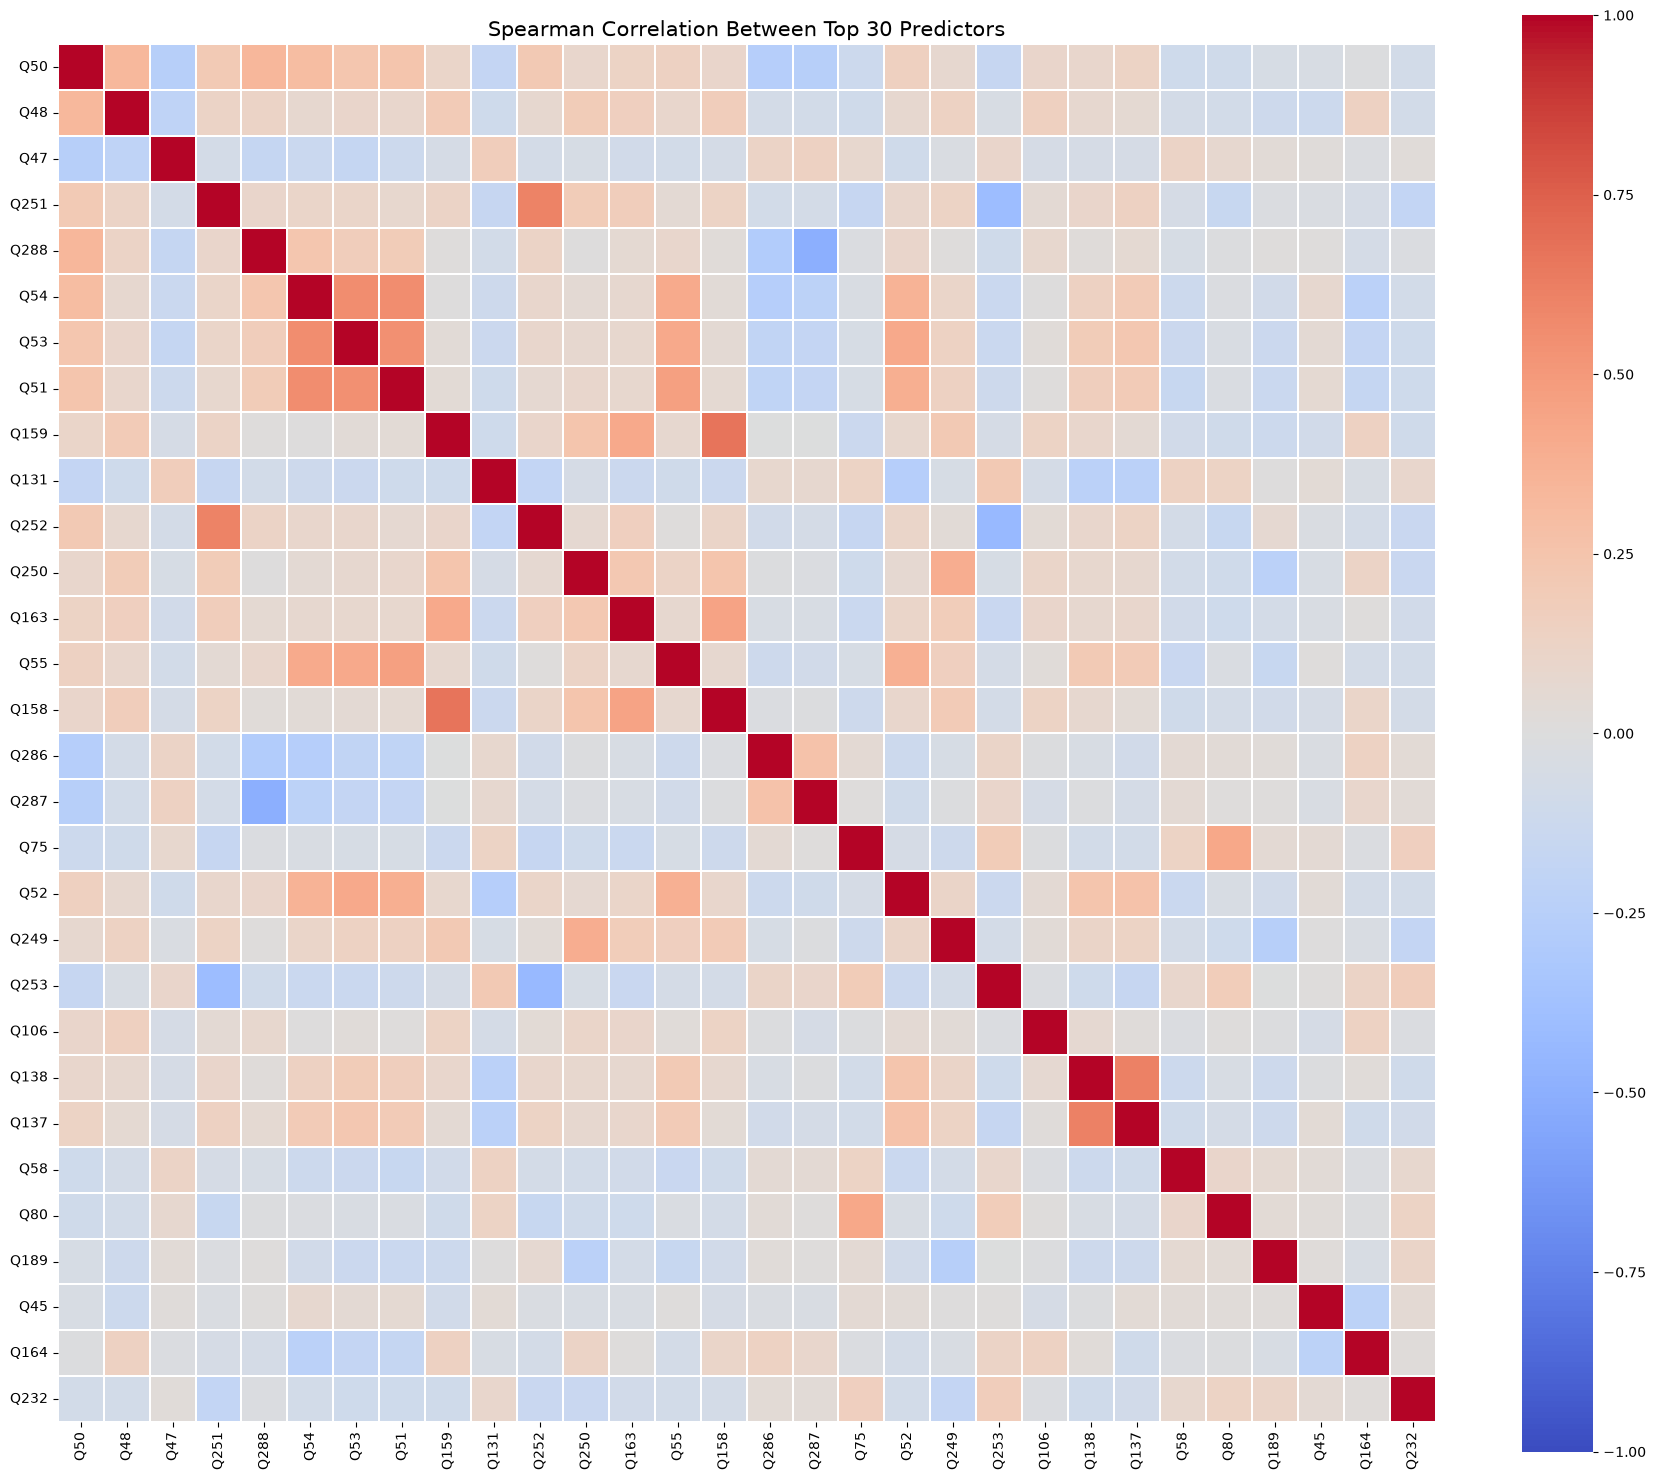

In [52]:
# Plot Top 30 feature-feature correlation heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    top30_corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3
)

plt.title(
    "Spearman Correlation Between Top 30 Predictors",
    fontsize=15
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "WVS_Top30_Feature_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
# Extract unique feature pairs
upper_triangle = np.triu(
    np.ones(top30_corr_matrix.shape),
    k=1
).astype(bool)

correlation_pairs = (
    top30_corr_matrix
    .where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Spearman_correlation"
]

correlation_pairs["Absolute_correlation"] = (
    correlation_pairs["Spearman_correlation"].abs()
)

# Sort by absolute correlation
correlation_pairs = correlation_pairs.sort_values(
    "Absolute_correlation",
    ascending=False
)

# Show all pairs with absolute correlation >= 0.70
high_correlation_pairs = correlation_pairs.loc[
    correlation_pairs["Absolute_correlation"] >= 0.70
].copy()

print("Number of highly correlated pairs:", len(high_correlation_pairs))

display(high_correlation_pairs.round(3))

Number of highly correlated pairs: 0


,Feature_1,Feature_2,Spearman_correlation,Absolute_correlation


### Top 30 Feature–Feature Correlation Analysis – Key Findings

Pairwise Spearman correlations were calculated among the 30 predictors with the strongest individual correlations with life satisfaction.

A total of 435 unique feature pairs were examined.

The analysis identified no pairs with an absolute Spearman correlation of 0.70 or higher.

This suggests that the selected Top 30 predictors do not exhibit strong pairwise correlations based on the chosen threshold. Therefore, no features were excluded at this stage due to high pairwise correlation.

However, the absence of highly correlated pairs does not rule out multicollinearity involving combinations of multiple predictors. Further assessment may be conducted using VIF and model-based feature analysis.

All 30 predictors will therefore be retained for the upcoming feature experiments.